<a href="https://colab.research.google.com/github/mohangowda2607-source/Assignment-1--Diabetes/blob/main/Assignment_1_Diabetes_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Diabetes Prediction using Machine Learning


---
# Part 1 — Data Preparation
## 1. Load the dataset using Pandas

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = glob.glob("/content/diabetes*.csv")[0]
data = pd.read_csv(DATA_PATH)
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Explore the dataset

In [2]:
# a. Shape of the dataset
print("Rows, columns:", data.shape)

# b. Column names
print("Columns:", list(data.columns))

Rows, columns: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [3]:
# c. Data types
data.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [4]:
# d. Missing values, if any
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [5]:
# e. Basic statistical summary
data.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


### A closer look at "missing values"
`isnull()` reports no missing values, but the summary above shows a **minimum of 0** for Glucose, BloodPressure, SkinThickness, Insulin and BMI. A living patient cannot have a blood pressure, BMI or glucose level of zero, so in these five columns a 0 means "not recorded". They are hidden missing values. (`Pregnancies` = 0 is a real value and is left alone.)

In [6]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

hidden = pd.DataFrame({
    "zeros": (data[zero_as_missing] == 0).sum(),
    "percent_of_rows": ((data[zero_as_missing] == 0).mean() * 100).round(1),
})
hidden

,zeros,percent_of_rows
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


         count  percent
Outcome                
0          500     65.1
1          268     34.9


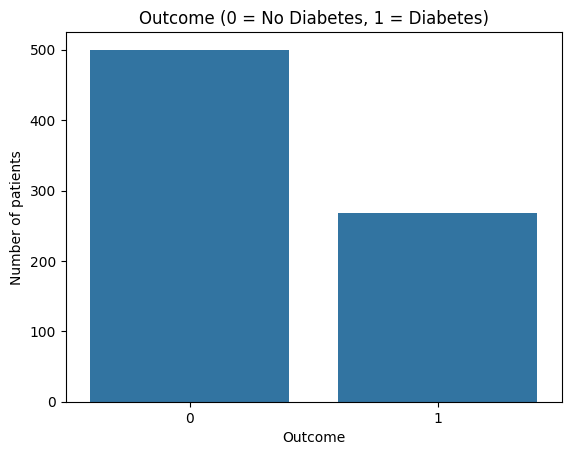

In [7]:
# Target distribution
counts = data["Outcome"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(data) * 100).round(1)}))

sns.countplot(x=data["Outcome"])
plt.title("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of patients")
plt.show()

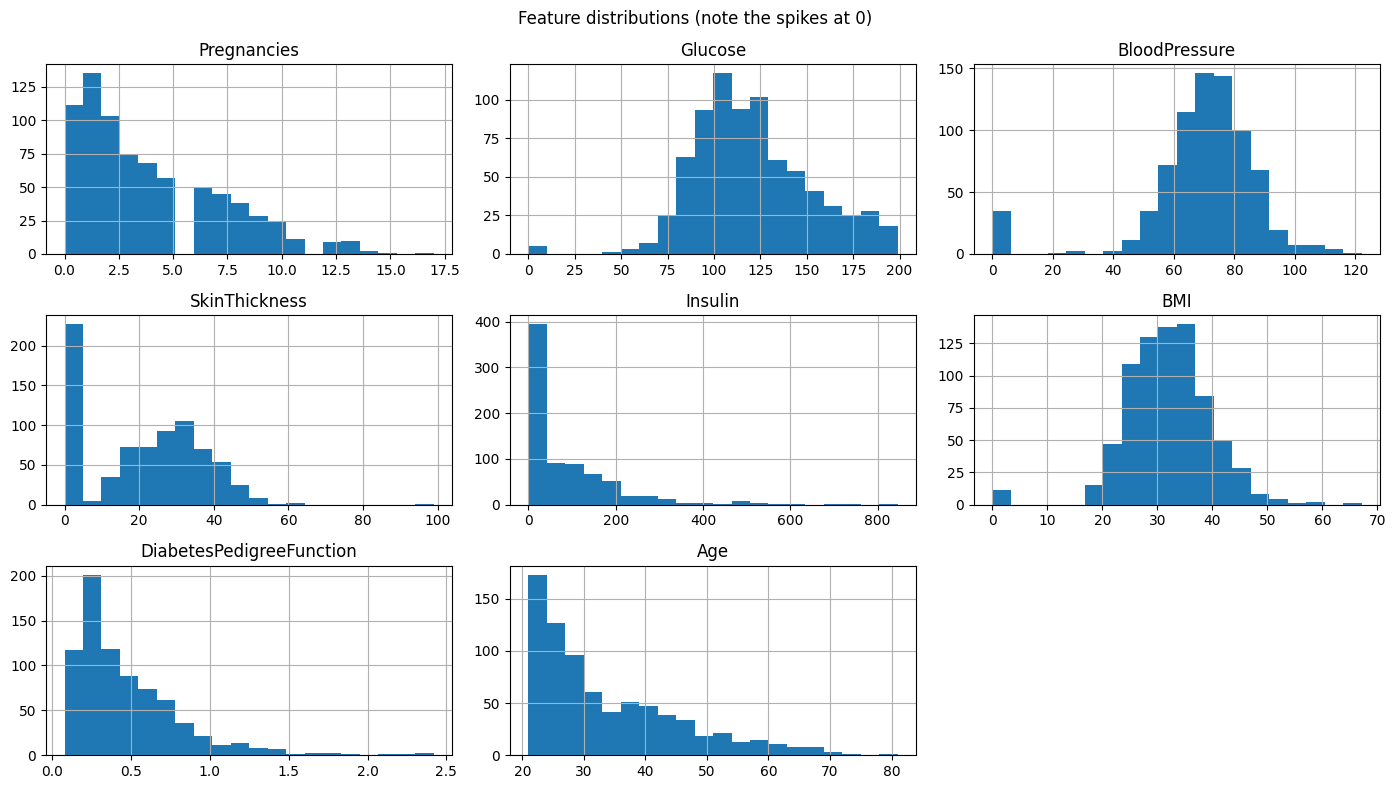

In [8]:
# Distribution of every feature
data.drop(columns="Outcome").hist(bins=20, figsize=(14, 8))
plt.suptitle("Feature distributions (note the spikes at 0)")
plt.tight_layout()
plt.show()

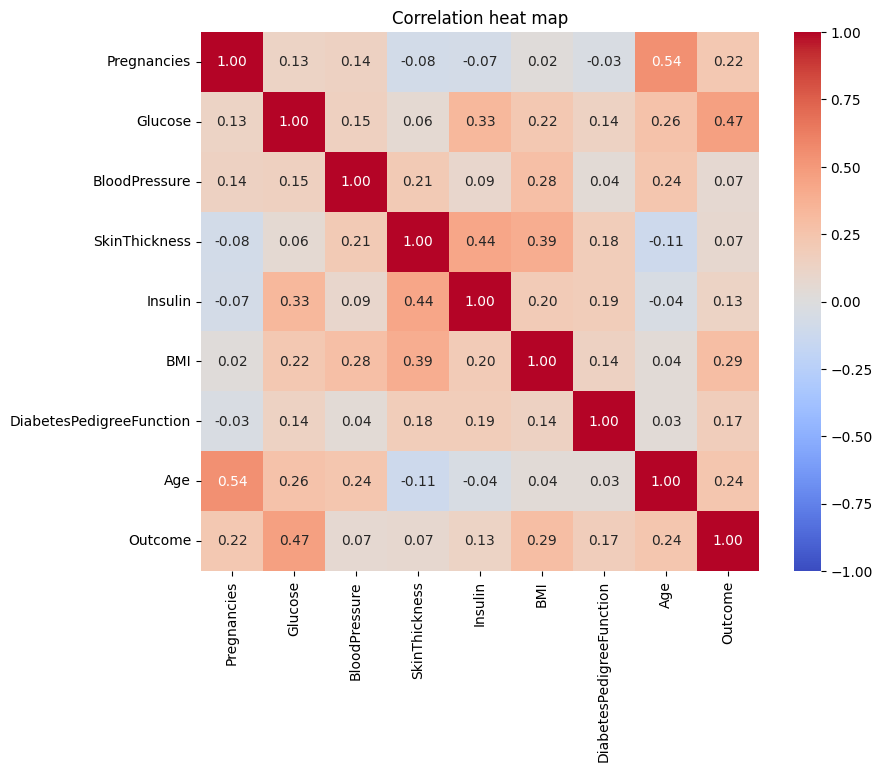

,Outcome
Glucose,0.47
BMI,0.29
Age,0.24
Pregnancies,0.22
DiabetesPedigreeFunction,0.17
Insulin,0.13
SkinThickness,0.07
BloodPressure,0.07


In [9]:
# Correlation with the target
plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heat map")
plt.show()

data.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(2)

### Deliverable — Dataset exploration summary

- **Size:** 768 rows (patients) and 9 columns.
- **Data types:** all numeric. Seven columns are integers; `BMI` and `DiabetesPedigreeFunction` are decimals. There are no categorical (text) columns.
- **Missing values:** none reported by `isnull()`, and no duplicate rows. However, zeros stand in for missing readings in five columns: Insulin 374 rows (48.7%), SkinThickness 227 (29.6%), BloodPressure 35 (4.6%), BMI 11 (1.4%) and Glucose 5 (0.7%).
- **Target balance:** 500 patients (65.1%) without diabetes and 268 (34.9%) with diabetes. The classes are imbalanced roughly 2 : 1, so accuracy alone can mislead: a model that always answers "No Diabetes" would already score 65%.
- **Scale:** the features sit on very different ranges, for example Insulin 0 to 846 against DiabetesPedigreeFunction 0.08 to 2.42.
- **Relationship with the target:** Glucose has the strongest correlation with Outcome (0.47), followed by BMI (0.29), Age (0.24) and Pregnancies (0.22). BloodPressure and SkinThickness are the weakest (0.07 each).

### Deliverable — Description of features and target variable

| Column | Role | Description |
|---|---|---|
| Pregnancies | Feature | Number of times pregnant |
| Glucose | Feature | Plasma glucose concentration |
| BloodPressure | Feature | Diastolic blood pressure |
| SkinThickness | Feature | Triceps skin fold thickness |
| Insulin | Feature | Serum insulin level |
| BMI | Feature | Body Mass Index |
| DiabetesPedigreeFunction | Feature | Diabetes pedigree score (family history) |
| Age | Feature | Age of the patient |
| **Outcome** | **Target** | 0 = No Diabetes, 1 = Diabetes |

All eight features are numeric and medically plausible predictors, so all are kept as inputs.

## 3. Separate the dataset into Features (X) and Target Variable (y)

In [10]:
X = data.drop(["Outcome"], axis=1)     # features: the 8 independent columns
y = data["Outcome"]                    # target variable: the dependent column

print("X:", X.shape)
print("y:", y.shape)

X: (768, 8)
y: (768,)


## 4. Perform a Train-Test Split
The split is done **before** any preprocessing so that nothing is learned from the test rows (no data leakage).

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% testing, 80% training
    random_state=42,     # same split on every run
    stratify=y           # keep the 65 / 35 class proportion in both sets
)

print("Training set:", X_train.shape, "| diabetic:", int(y_train.sum()), "| non-diabetic:", int((y_train == 0).sum()))
print("Testing set :", X_test.shape,  "| diabetic:", int(y_test.sum()),  "| non-diabetic:", int((y_test == 0).sum()))

Training set: (614, 8) | diabetic: 214 | non-diabetic: 400
Testing set : (154, 8) | diabetic: 54 | non-diabetic: 100


## 5. Perform appropriate preprocessing
### a. Handle missing values

In [13]:
from sklearn.impute import SimpleImputer

# Step 1: mark the impossible zeros as missing (NaN) in both sets
X_train = X_train.copy()
X_test = X_test.copy()
X_train[zero_as_missing] = X_train[zero_as_missing].replace(0, np.nan)
X_test[zero_as_missing] = X_test[zero_as_missing].replace(0, np.nan)

print("Missing values in the training set after marking zeros:")
print(X_train.isnull().sum())

Missing values in the training set after marking zeros:
Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [14]:
# Step 2: fill them with the MEDIAN, learned from the training set only
imputer = SimpleImputer(strategy="median")
X_train_filled = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_filled = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print("Median used for each column (from training data):")
print(pd.Series(imputer.statistics_, index=X.columns))
print("\nMissing values left:", int(X_train_filled.isnull().sum().sum()), "in train,", int(X_test_filled.isnull().sum().sum()), "in test")

Median used for each column (from training data):
Pregnancies                   3.0000
Glucose                     117.0000
BloodPressure                72.0000
SkinThickness                29.0000
Insulin                     125.0000
BMI                          32.4000
DiabetesPedigreeFunction      0.3825
Age                          29.0000
dtype: float64

Missing values left: 0 in train, 0 in test


### c. Scale / standardize numerical features

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_filled)   # learn mean and standard deviation from TRAIN
X_test_scaled = scaler.transform(X_test_filled)         # apply the same values to TEST

pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[["mean", "std", "min", "max"]].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.15,-2.19,-3.92,-2.48,-1.56,-2.09,-1.19,-1.05
max,3.98,2.58,4.07,7.87,7.70,5.08,5.61,4.03


### Deliverable — Preprocessing steps performed

1. **Split first** (80 / 20, stratified, `random_state=42`) so that every later step is learned from training data only.
2. **Missing values:** zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI were converted to missing and filled with the **training-set median** of each column (Glucose 117, BloodPressure 72, SkinThickness 29, Insulin 125, BMI 32.4). The median is used instead of the mean because Insulin and SkinThickness are skewed with extreme values, and the median is not pulled by them. Rows were not dropped, because that would discard about half the dataset (Insulin alone is missing in 48.7% of rows).
3. **Encoding:** none needed; there are no categorical columns.
4. **Scaling:** all eight features were standardised (mean 0, standard deviation 1) with `StandardScaler`, fitted on the training set. Logistic Regression is trained by gradient-based optimisation and works better, and gives comparable coefficients, when features share a scale.

### Deliverable — Training and testing dataset sizes

| Set | Rows | Columns | Diabetic | Non-diabetic |
|---|---|---|---|---|
| Training | 614 (80%) | 8 | 214 | 400 |
| Testing | 154 (20%) | 8 | 54 | 100 |

---
# Part 2 — Machine Learning Model Building
## 1. Import the required libraries

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

## 2. Select and implement a classification algorithm — Logistic Regression

In [17]:
model = LogisticRegression(max_iter=1000)     # max_iter raised so the solver always converges
model

LogisticRegression(max_iter=1000)

## 3. Train the model using the training dataset

In [18]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

## 4. Why Logistic Regression is suitable for this problem

### Deliverable — Explanation of the selected algorithm

- **The problem is binary classification.** The target has two classes, 0 (No Diabetes) and 1 (Diabetes), which is exactly what Logistic Regression is designed for.
- **It outputs a probability.** The model combines the features into a weighted sum and passes it through the sigmoid function to get a value between 0 and 1: the estimated probability of diabetes. A patient is classified as diabetic when that probability is at least 0.5. In a medical setting a probability ("72% risk") is more useful than a bare yes or no, and the threshold can be moved to catch more cases.
- **It is interpretable.** Each feature gets one coefficient, so we can say which measurements raise or lower the predicted risk. This matters when results must be explained to clinicians.
- **It suits the data.** All eight features are numeric, the dataset is small (768 rows), and a simple linear model is less likely to overfit than a complex one.
- **It is a sound baseline.** It trains in a fraction of a second and sets a reference score that any more complex model must beat.

---
# Part 3 — Model Training and Evaluation
## 1. Fit the selected model using the training dataset
Done in Part 2, step 3. The fitted parameters:

In [19]:
print("Intercept:", round(float(model.intercept_[0]), 3))
coefficients = pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False).round(3)
coefficients

Intercept: -0.872


,0
Glucose,1.183
BMI,0.689
Pregnancies,0.377
DiabetesPedigreeFunction,0.233
Age,0.148
SkinThickness,0.028
BloodPressure,-0.044
Insulin,-0.066


## 2. Generate predictions on the training dataset

In [20]:
train_predictions = model.predict(X_train_scaled)
train_predictions[:20]

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0])

## 3. Evaluate the model's performance on the training data — accuracy

In [21]:
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training accuracy:", round(train_accuracy, 4))

Training accuracy: 0.7964


### Deliverable — Model training output and training accuracy
The model was fitted on 614 training rows and converged without warnings. **Training accuracy: 79.64%** (489 of 614 patients classified correctly).

## Testing: generate predictions on the test dataset and evaluate

In [22]:
test_predictions = model.predict(X_test_scaled)
test_probabilities = model.predict_proba(X_test_scaled)[:, 1]     # probability of diabetes

test_accuracy = accuracy_score(y_test, test_predictions)
print("Test accuracy:", round(test_accuracy, 4))
print("Precision    :", round(precision_score(y_test, test_predictions), 4))
print("Recall       :", round(recall_score(y_test, test_predictions), 4))
print("F1-Score     :", round(f1_score(y_test, test_predictions), 4))
print()
print(classification_report(y_test, test_predictions, target_names=["No Diabetes", "Diabetes"]))

Test accuracy: 0.7078
Precision    : 0.6
Recall       : 0.5
F1-Score     : 0.5455

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



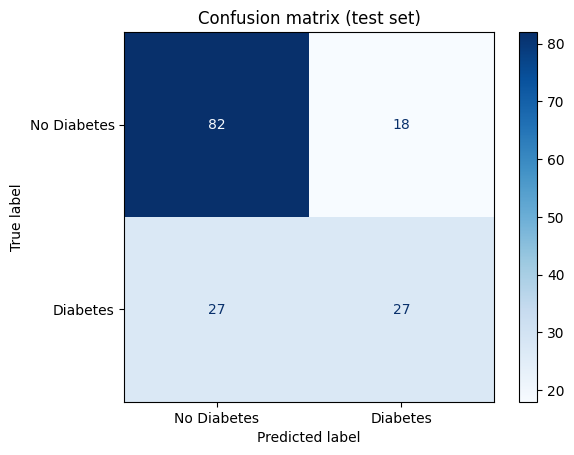

True negatives 82 | False positives 18 | False negatives 27 | True positives 27


In [23]:
# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives {tn} | False positives {fp} | False negatives {fn} | True positives {tp}")

## Compare the training and testing performance

In [24]:
comparison = pd.DataFrame({
    "Training": [accuracy_score(y_train, train_predictions), precision_score(y_train, train_predictions),
                 recall_score(y_train, train_predictions), f1_score(y_train, train_predictions)],
    "Testing":  [test_accuracy, precision_score(y_test, test_predictions),
                 recall_score(y_test, test_predictions), f1_score(y_test, test_predictions)],
}, index=["Accuracy", "Precision", "Recall", "F1-Score"]).round(4)
comparison["Difference"] = (comparison["Training"] - comparison["Testing"]).round(4)
comparison

,Training,Testing,Difference
Accuracy,0.7964,0.7078,0.0886
Precision,0.7697,0.6000,0.1697
Recall,0.5935,0.5000,0.0935
F1-Score,0.6702,0.5455,0.1247


### Deliverables — test results

| Metric | Training | Testing |
|---|---|---|
| Accuracy | 79.64% | **70.78%** |
| Precision (Diabetes) | 0.770 | **0.600** |
| Recall (Diabetes) | 0.593 | **0.500** |
| F1-Score (Diabetes) | 0.670 | **0.545** |

**Confusion matrix (test set, 154 patients)**

| | Predicted No Diabetes | Predicted Diabetes |
|---|---|---|
| **Actual No Diabetes (100)** | 82 true negatives | 18 false positives |
| **Actual Diabetes (54)** | 27 false negatives | 27 true positives |

**Comparison of training vs. testing performance.** Accuracy falls from 79.6% on training data to 70.8% on unseen data, a gap of about 9 points. Some drop is expected, since the model has already seen the training rows. A gap this size suggests mild overfitting, but with only 154 test patients each patient is worth 0.65 points, so part of it is down to which rows landed in the test set (Part 4 checks this with cross-validation).

**Brief interpretation of the model results.**
- The model is right for about 7 patients in 10. That is better than the 65% obtained by always predicting "No Diabetes", but not by a wide margin.
- It is much better at recognising non-diabetic patients (82 of 100 correct) than diabetic ones (27 of 54).
- **Recall of 0.50 is the main weakness:** half of the patients who do have diabetes are missed. In a screening context these false negatives are the costly error, because an undiagnosed patient goes untreated.
- Precision of 0.60 means that when the model flags diabetes it is right 6 times in 10; the other 4 are false alarms, which lead to an unnecessary follow-up test rather than to harm.

---
# Part 4 — Model Performance Analysis
The task list for this part is cut off in the assignment PDF, so this section analyses overall performance from four angles and then draws conclusions.

### 4.1 Which features drive the prediction?

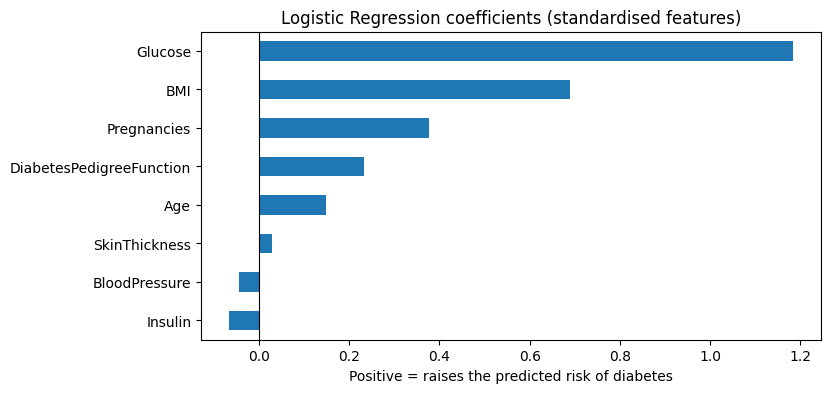

In [25]:
coefficients.sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Logistic Regression coefficients (standardised features)")
plt.xlabel("Positive = raises the predicted risk of diabetes")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

### 4.2 How well does the model separate the two classes? (ROC curve)

ROC AUC: 0.813


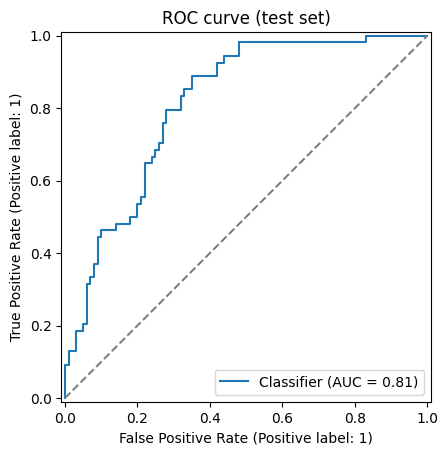

In [26]:
print("ROC AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.title("ROC curve (test set)")
plt.show()

### 4.3 Can recall be improved by moving the decision threshold?
`predict()` classifies a patient as diabetic when the probability is at least 0.5. Lowering that threshold flags more patients.

In [27]:
rows = []
for threshold in [0.5, 0.4, 0.3]:
    p = (test_probabilities >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": threshold,
                 "accuracy": round(accuracy_score(y_test, p), 3),
                 "precision": round(precision_score(y_test, p), 3),
                 "recall": round(recall_score(y_test, p), 3),
                 "missed diabetics (FN)": fn_,
                 "false alarms (FP)": fp_})
pd.DataFrame(rows)

,threshold,accuracy,precision,recall,missed diabetics (FN),false alarms (FP)
0,0.5,0.708,0.600,0.500,27,18
1,0.4,0.734,0.614,0.648,19,22
2,0.3,0.740,0.597,0.796,11,29


### 4.4 Is the test score a fair estimate? (5-fold cross-validation)
One 80 / 20 split gives one number that depends on which rows fell into the test set. Cross-validation repeats the whole process on five different splits. The imputer and scaler sit inside a pipeline so they are re-fitted on each training fold, which keeps the check free of leakage.

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

X_marked = X.copy()
X_marked[zero_as_missing] = X_marked[zero_as_missing].replace(0, np.nan)

pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipeline, X_marked, y, cv=folds, scoring="accuracy")

print("Accuracy on each fold:", cv_scores.round(3))
print(f"Mean accuracy: {cv_scores.mean():.3f}  +/- {cv_scores.std():.3f}")

Accuracy on each fold: [0.773 0.799 0.779 0.752 0.758]
Mean accuracy: 0.772  +/- 0.017


### Conclusions

**Overall performance.** Logistic Regression reaches 70.8% accuracy on the held-out test set and a ROC AUC of 0.81. The AUC shows the model ranks patients by risk reasonably well; the modest accuracy and recall come mainly from where the 0.5 cut-off sits, not from an inability to separate the classes.

**How reliable is the 70.8%?** Five-fold cross-validation gives 77.2% on average with a spread of ±1.7 points (folds between 75.2% and 79.9%). The single test split is therefore on the pessimistic side, and about 77% is the fairer estimate of accuracy on new patients. It also means the 9-point train/test gap overstates the overfitting.

**What drives the prediction.** Glucose is by far the strongest factor (coefficient +1.18), followed by BMI (+0.69) and Pregnancies (+0.38). DiabetesPedigreeFunction (+0.23) and Age (+0.15) add a little. BloodPressure, SkinThickness and Insulin are close to zero and contribute almost nothing. This matches medical expectation, since plasma glucose is the direct marker of diabetes, and it matches the correlations seen in Part 1.

**Analytical / business insight.** For a screening tool the default threshold is the wrong operating point. At 0.5 the model misses 27 of 54 diabetic patients. Lowering the threshold to 0.3 cuts the misses to 11 (recall 0.80) while false alarms rise from 18 to 29, and accuracy even improves slightly to 74.0%. Because a missed diabetic costs far more than an extra confirmatory test, a threshold near 0.3 is the better choice here.

**Limitations.**
- The dataset is small (768 patients), so every estimate carries noticeable uncertainty.
- Nearly half of the Insulin values and 30% of SkinThickness values were missing and had to be filled with a median, which weakens those two features.
- The classes are imbalanced 65 / 35, which pulls the model towards predicting "No Diabetes".
- Logistic Regression draws a straight-line boundary; it cannot capture interactions such as high glucose mattering more at higher BMI.

**How it could be improved.** Use `class_weight="balanced"` or a lower threshold to raise recall; try tree-based models such as Random Forest and compare them by cross-validation; collect complete Insulin and SkinThickness readings; and report recall and AUC alongside accuracy.

**Conclusion.** The model is a reasonable baseline: it is clearly better than guessing, easy to explain, and identifies glucose and BMI as the key risk indicators. At the default threshold it misses too many diabetic patients to be used for screening as it stands; with a lowered threshold it becomes a useful first-pass risk flag that supports, but does not replace, a clinical test.